# From CNNs to Object Detection: Training a YOLO Wildlife Detector
**Level:** Intermediate · **Runtime:** Google Colab (GPU: T4)

> **Every cell is complete. No coding needed.** Run the cells top to bottom (`Runtime → Run all` works too).

### What you'll build
A custom YOLO detector that finds **buffalo, elephants, rhinos and zebras** in photos: trained, evaluated and debugged step by step.

### Learning objectives
By the end of this session you will understand how to:
1. Explain how object detection differs from the image classification CNNs we studied
2. Compute **IoU** and **Non-Maximum Suppression (NMS)** from scratch in NumPy
3. Read and convert the **YOLO label format**
4. Fine-tune a pretrained YOLO model with **transfer learning**
5. Interpret **precision, recall, mAP@50 and mAP@50-95**
6. Run a **failure analysis** to find out *where* and *why* your model makes mistakes

### Session plan
| Part | Topic |
|---|---|
| 0 | Setup and CNN → detection recap |
| 1 | Bounding boxes and **IoU from scratch** |
| 2 | **NMS from scratch** |
| 3 | Pretrained YOLO26 in action |
| 4 | Exploring the dataset and the YOLO label format |
| 5 | **Training** (theory discussion while the GPU works) |
| 6 | Evaluation and **failure analysis** |
| 7 | Inference on new images and export |
| 8 | Take-home challenge |

---
## Part 0: Setup

**Before anything else:** `Runtime → Change runtime type → T4 GPU`. Training on a CPU would take hours.

In [1]:
!pip install -q -U ultralytics

import ultralytics, torch
ultralytics.checks()
print("GPU available:", torch.cuda.is_available())

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)
GPU available: True


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2, random, glob
from pathlib import Path
from collections import Counter
from PIL import Image
from ultralytics import YOLO

random.seed(0)
np.random.seed(0)

def show(img_bgr_or_rgb, title=None, bgr=True, size=(8, 6)):
    # Display an image inline (OpenCV images are BGR, matplotlib expects RGB)
    img = img_bgr_or_rgb[:, :, ::-1] if bgr else img_bgr_or_rgb
    plt.figure(figsize=size); plt.imshow(img); plt.axis("off")
    if title: plt.title(title)
    plt.show()

### Recap: from classification to detection
| | Image classification (what we built) | Object detection (today) |
|---|---|---|
| Question | *What* is in the image? | *What* is in it and *where*? |
| Output | 1 label + probability | N boxes × (x, y, w, h, class, confidence) |
| Architecture | CNN backbone → flatten → dense → softmax | CNN **backbone** → **neck** (multi-scale fusion) → **detection head** |
| Loss | Cross-entropy | Box regression loss + classification loss |

**Key idea:** The **backbone** in YOLO is the same convolution → activation → downsampling stack we studied. Early layers detect edges and textures, deeper layers detect parts and objects. YOLO keeps feature maps at **several resolutions**: small feature maps (deep, coarse) are good for big objects, larger feature maps (shallow, fine) for small objects. It predicts boxes on all of them **in a single forward pass**, which is where "You Only Look Once" comes from.

---
## Part 1: Bounding Boxes and IoU

### Two box formats you'll meet constantly
- **xyxy**: `(x1, y1, x2, y2)`: top-left and bottom-right corners, in pixels. Used for drawing and for IoU.
- **xywh (YOLO)**: `(x_center, y_center, width, height)`, **normalized to 0 to 1** by the image size. Used in label files.

### Intersection over Union (IoU)
$$\text{IoU} = \frac{\text{area of overlap}}{\text{area of union}} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$

- IoU = 1: perfect overlap. IoU = 0: no overlap.
- A prediction usually counts as **correct** if IoU ≥ 0.5 with a ground-truth box of the same class.
- How it's computed: the intersection's top-left corner is the **max** of the two top-left corners, and its bottom-right corner is the **min** of the two bottom-right corners. If the boxes don't overlap, the width or height goes negative, so it's clipped to 0.

### Box format conversion and IoU in code

In [3]:
# Box format conversion and IoU
def yolo_to_xyxy(xc, yc, w, h, img_w, img_h):
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return x1, y1, x2, y2

def iou(box_a, box_b):
    # Intersection: max of top-left corners, min of bottom-right corners (clipped to 0)
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

# Tests
assert np.allclose(yolo_to_xyxy(0.5, 0.5, 0.5, 0.5, 640, 480), (160, 120, 480, 360))
assert iou((0, 0, 10, 10), (0, 0, 10, 10)) == 1.0          # identical
assert iou((0, 0, 10, 10), (20, 20, 30, 30)) == 0.0        # disjoint
assert abs(iou((0, 0, 10, 10), (5, 0, 15, 10)) - 1/3) < 1e-9  # half-overlap -> 50/150
print("All tests passed")

All tests passed


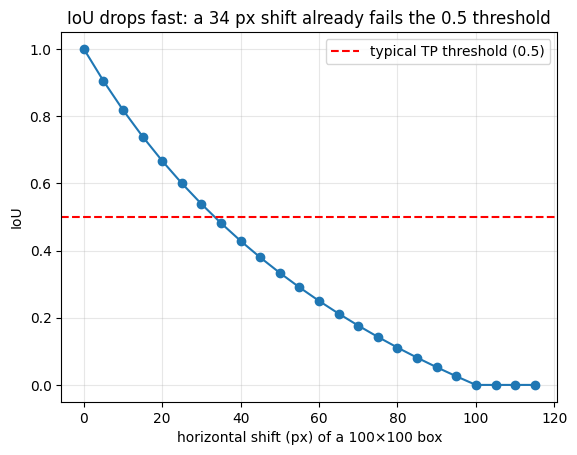

In [4]:
# Visual intuition: how does IoU change as one box slides across another?
gt = (100, 100, 200, 200)
shifts = range(0, 120, 5)
vals = [iou(gt, (100 + s, 100, 200 + s, 200)) for s in shifts]
plt.plot(list(shifts), vals, marker="o")
plt.axhline(0.5, ls="--", c="r", label="typical TP threshold (0.5)")
plt.xlabel("horizontal shift (px) of a 100×100 box"); plt.ylabel("IoU"); plt.legend(); plt.grid(alpha=.3)
plt.title("IoU drops fast: a 34 px shift already fails the 0.5 threshold")
plt.show()

**Discussion:** A shift of only about a third of the box width drops IoU below 0.5. Why does that make **mAP@50-95** (which averages IoU thresholds from 0.50 to 0.95) a much stricter metric than mAP@50?

---
## Part 2: Non-Maximum Suppression

A detector outputs many overlapping candidate boxes for the same object. **NMS** removes the duplicates:

1. Sort boxes by confidence, highest first
2. Keep the top box
3. Remove every remaining box whose IoU with it is above a threshold (e.g. 0.5)
4. Repeat with what's left

The cell below implements NMS with the `iou` function from Part 1, then shows it on simulated detections.

12 raw boxes -> 2 after NMS


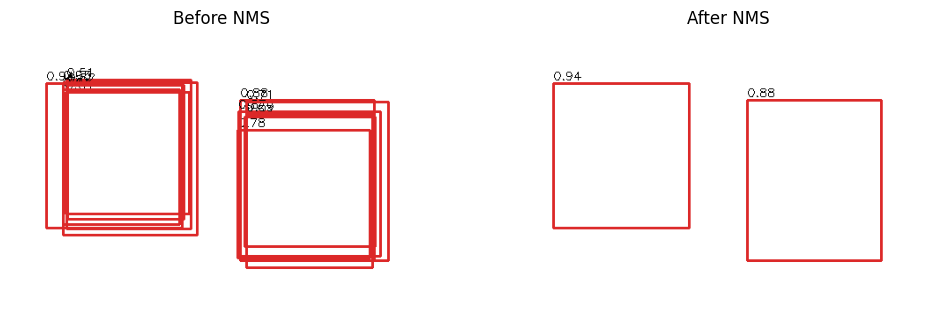

In [5]:
# Non-Maximum Suppression
def nms(boxes, scores, iou_thr=0.5):
    order = list(np.argsort(scores)[::-1])
    keep = []
    while order:
        best = order.pop(0)
        keep.append(best)
        order = [i for i in order if iou(boxes[best], boxes[i]) < iou_thr]
    return keep

# Simulated raw detector output: two objects, with several noisy duplicates each
rng = np.random.default_rng(1)
objects = [(60, 60, 200, 220), (260, 90, 420, 260)]
boxes, scores = [], []
for (x1, y1, x2, y2) in objects:
    for _ in range(6):
        j = rng.normal(0, 10, 4)
        boxes.append((x1 + j[0], y1 + j[1], x2 + j[2], y2 + j[3]))
        scores.append(float(rng.uniform(0.5, 0.95)))

keep = nms(boxes, scores, iou_thr=0.5)
print(f"{len(boxes)} raw boxes -> {len(keep)} after NMS")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, idxs, title in [(axes[0], range(len(boxes)), "Before NMS"), (axes[1], keep, "After NMS")]:
    canvas = np.full((320, 480, 3), 255, np.uint8)
    for i in idxs:
        b = tuple(int(v) for v in boxes[i])
        cv2.rectangle(canvas, b[:2], b[2:], (220, 40, 40), 2)
        cv2.putText(canvas, f"{scores[i]:.2f}", (b[0], b[1] - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1)
    ax.imshow(canvas); ax.set_title(title); ax.axis("off")
plt.show()

### Instructor talking point: YOLO26 is NMS-free
Classic YOLO models (v5, v8, YOLO11) run exactly this algorithm as a **post-processing step**. **YOLO26**, the model we use today, is trained **end-to-end** to output one box per object directly, so it doesn't need NMS at inference time.

**Discussion:** Why would removing NMS make deployment faster and simpler, especially on edge devices like phones or a Raspberry Pi? *(Hint: NMS is a sequential loop. What happens when there are 500 candidate boxes?)*

---
## Part 3: Pretrained YOLO26 in Action

The pretrained model was trained on **COCO**, a dataset with 80 everyday classes (person, car, dog, bus, and so on).

Number of classes: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow'] ...


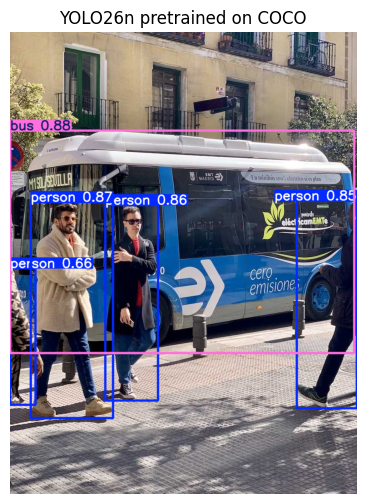

In [6]:
model = YOLO("yolo26n.pt")      # n = nano, the smallest and fastest variant
print("Number of classes:", len(model.names))
print(list(model.names.values())[:20], "...")

results = model("https://ultralytics.com/images/bus.jpg", verbose=False)
r = results[0]
show(r.plot(), "YOLO26n pretrained on COCO")

In [7]:
# What does the model actually return? Look inside the Results object
print("Boxes (xyxy, pixels):\n", r.boxes.xyxy.cpu().numpy().round(1))
print("Confidences:", r.boxes.conf.cpu().numpy().round(3))
print("Class ids:  ", r.boxes.cls.cpu().numpy().astype(int))
print("Class names:", [model.names[int(c)] for c in r.boxes.cls])
print("Speed (ms):", {k: round(v, 1) for k, v in r.speed.items()})

Boxes (xyxy, pixels):
 [[          0       230.5       803.2       750.7]
 [       48.6       397.7       240.3       902.4]
 [      222.9       404.8       345.5         861]
 [      669.6       394.5       809.9       879.4]
 [        0.2         553        59.7       871.3]]
Confidences: [      0.881       0.872       0.861       0.846       0.656]
Class ids:   [5 0 0 0 0]
Class names: ['bus', 'person', 'person', 'person', 'person']
Speed (ms): {'preprocess': 87.6, 'inference': 13.9, 'postprocess': 42.3}


### The confidence threshold trade-off
Run the same image at different `conf` thresholds. Watch what happens to the number of boxes.

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg


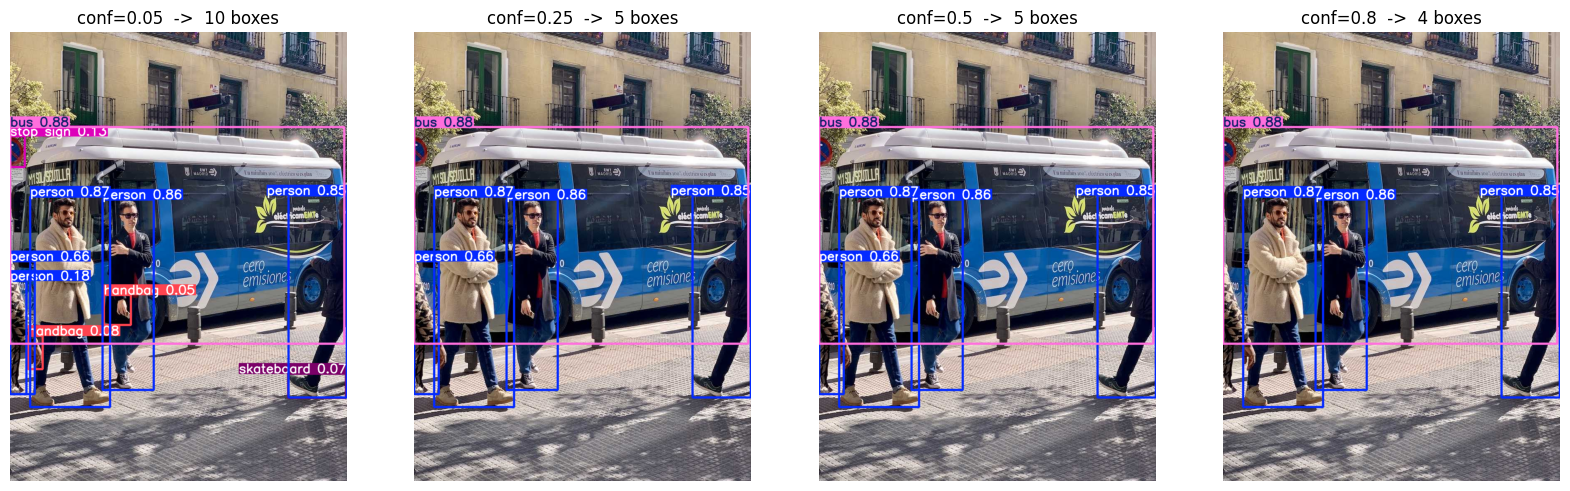

In [8]:
thresholds = [0.05, 0.25, 0.5, 0.8]
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, t in zip(axes, thresholds):
    res = model("https://ultralytics.com/images/bus.jpg", conf=t, verbose=False)[0]
    ax.imshow(res.plot()[:, :, ::-1]); ax.axis("off")
    ax.set_title(f"conf={t}  ->  {len(res.boxes)} boxes")
plt.show()

**Discussion:**
- Low threshold → more boxes → **higher recall, lower precision** (more false positives)
- High threshold → fewer boxes → **higher precision, lower recall** (more missed objects)
- Which would you choose for a **self-driving car** detecting pedestrians? And for a **spam-photo filter**?

**Optional:** Upload a photo (folder icon on the left), set `MY_PHOTO` in the next cell and run it.

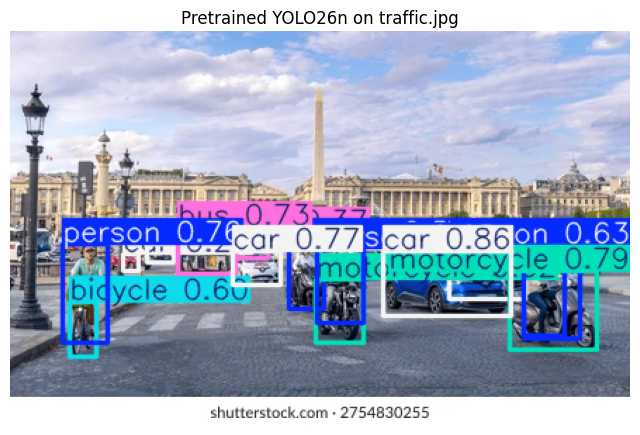

In [9]:
# Optional: run the pretrained model on your own photo (leave as None to skip)
MY_PHOTO = "traffic.jpg"          # e.g. "my_photo.jpg"
if MY_PHOTO:
    show(model(MY_PHOTO, verbose=False)[0].plot(), f"Pretrained YOLO26n on {MY_PHOTO}")
else:
    print("No photo set; skipping.")

---
## Part 4: The Dataset and the YOLO Label Format

COCO has no rhino class. To teach the model something **new**, we'll fine-tune it on the **African Wildlife** dataset (4 classes: buffalo, elephant, rhino, zebra; about 1,500 images). Ultralytics downloads it automatically.

In [10]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("african-wildlife.yaml")   # downloads (~100 MB) on first run
names = data["names"]
print("Classes:", names)
for split in ["train", "val", "test"]:
    if data.get(split):
        n = len(glob.glob(str(Path(data[split]) / "*.jpg")))
        print(f"{split:>5}: {n} images  ({data[split]})")


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 3.1Kfiles/s 1.0s
Dataset download success ✅ (1.7s), saved to /content/datasets

Classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
train: 1049 images  (/content/datasets/african-wildlife/images/train)
  val: 225 images  (/content/datasets/african-wildlife/images/val)
 test: 227 images  (/content/datasets/african-wildlife/images/test)


### Anatomy of a YOLO dataset
```
african-wildlife/
├── images/train/  1.jpg  2.jpg ...
├── labels/train/  1.txt  2.txt ...    <- same filename, .txt extension
├── images/val/ ...   labels/val/ ...
└── images/test/ ...  labels/test/ ...
```
Each `.txt` file has **one line per object**:
```
<class_id> <x_center> <y_center> <width> <height>     # all normalized 0 to 1
```

In [11]:
def label_path(img_path):
    # images/xxx/name.jpg  ->  labels/xxx/name.txt
    p = Path(img_path)
    return Path(str(p.parent).replace("images", "labels")) / (p.stem + ".txt")

def load_gt(img_path):
    # Return a list of (class_id, (x1,y1,x2,y2) in pixels) for one image
    W, H = Image.open(img_path).size
    lp = label_path(img_path)
    out = []
    if lp.exists():
        for line in lp.read_text().strip().splitlines():
            c, xc, yc, w, h = line.split()
            out.append((int(c), yolo_to_xyxy(float(xc), float(yc), float(w), float(h), W, H)))
    return out

train_imgs = sorted(glob.glob(str(Path(data["train"]) / "*.jpg")))
sample = random.choice(train_imgs)
print("Image:", sample)
print("Raw label file:\n" + label_path(sample).read_text())

Image: /content/datasets/african-wildlife/images/train/3 (88).jpg
Raw label file:
2 0.565000 0.588750 0.760000 0.562500



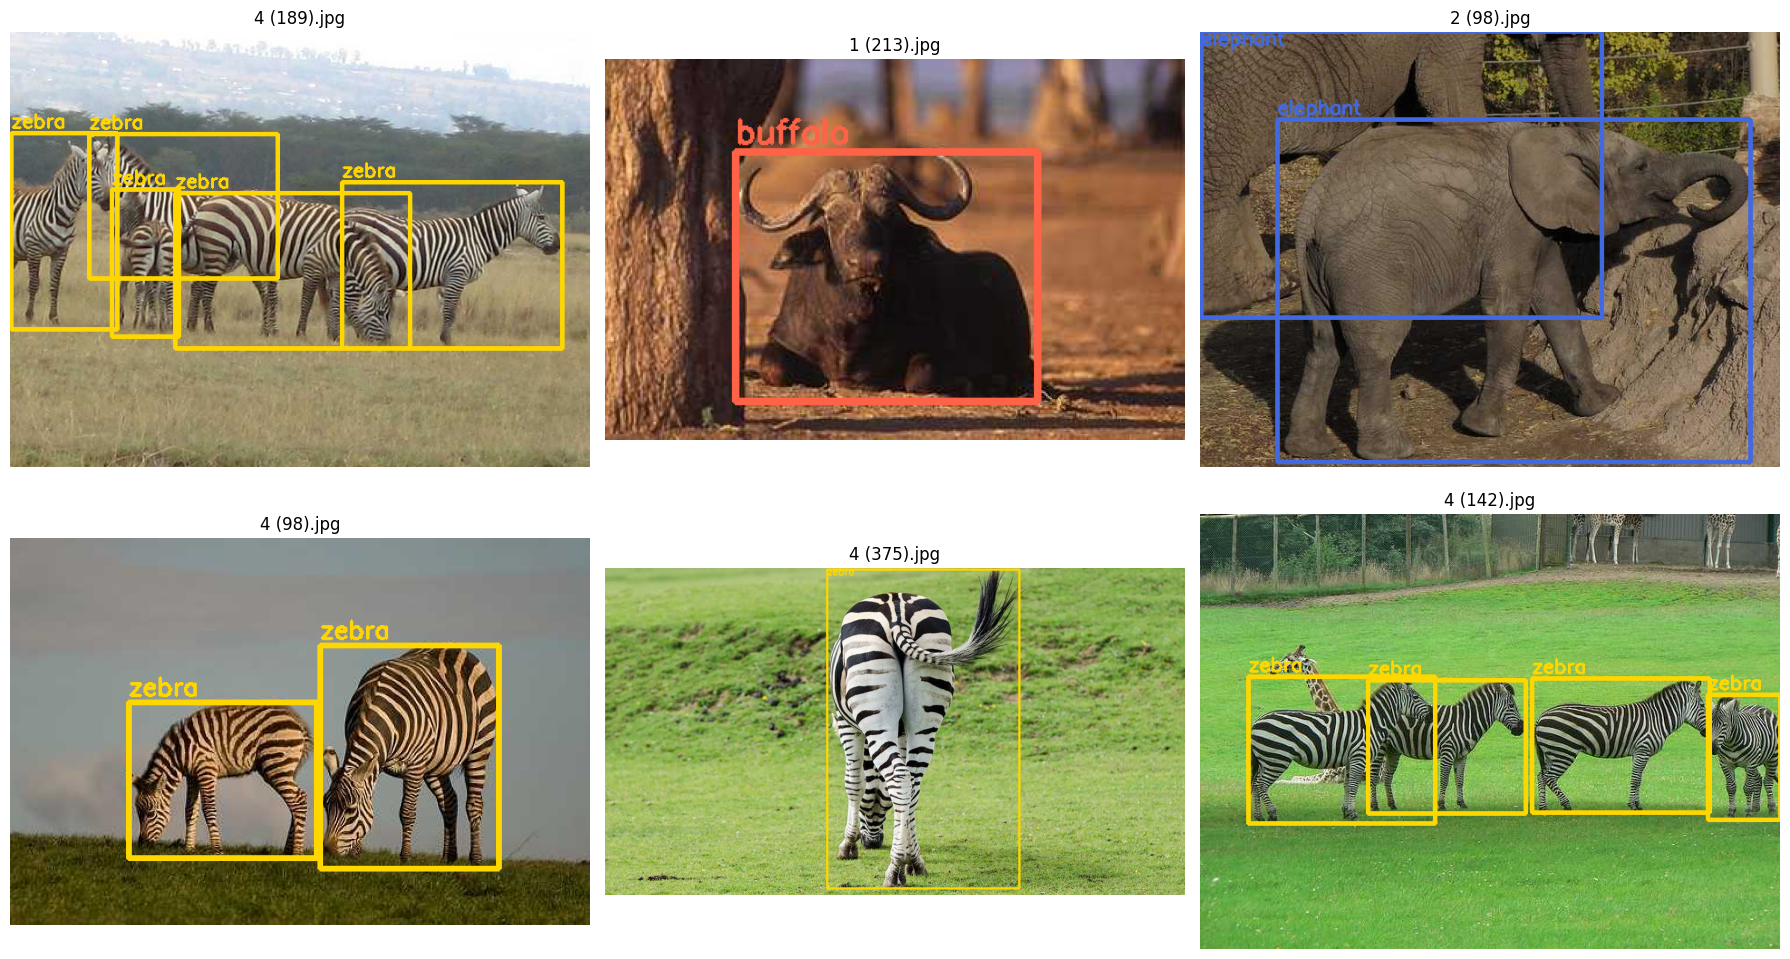

In [12]:
# Draw the ground-truth boxes for 6 random training images
# (labels converted with yolo_to_xyxy from Part 1)
COLORS = [(255, 99, 71), (65, 105, 225), (50, 205, 50), (255, 215, 0)]

def draw_boxes(img, items, color=None, thickness=3):
    for it in items:
        c, b = it[0], it[-1]
        x1, y1, x2, y2 = map(int, b)
        col = color or COLORS[c % len(COLORS)]
        cv2.rectangle(img, (x1, y1), (x2, y2), col, thickness)
        label = names[c] + (f" {it[1]:.2f}" if len(it) == 3 else "")
        cv2.putText(img, label, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    return img

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, p in zip(axes.flat, random.sample(train_imgs, 6)):
    img = cv2.imread(p)[:, :, ::-1].copy()       # RGB
    draw_boxes(img, load_gt(p))
    ax.imshow(img); ax.axis("off"); ax.set_title(Path(p).name)
plt.tight_layout(); plt.show()

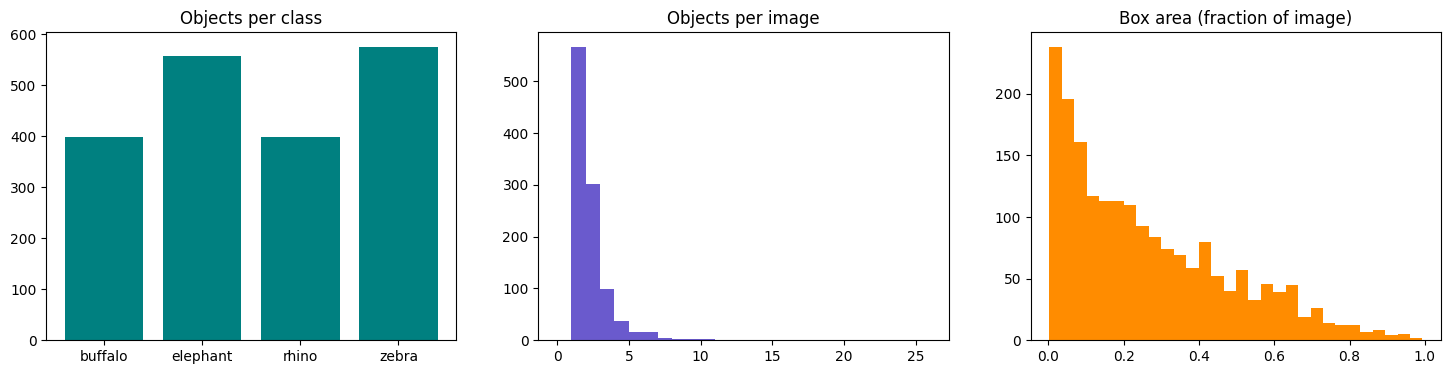

In [13]:
# Exploratory analysis: class balance and objects per image
cls_counts, per_img, box_areas = Counter(), [], []
for p in train_imgs:
    lp = label_path(p)
    lines = lp.read_text().strip().splitlines() if lp.exists() else []
    per_img.append(len(lines))
    for line in lines:
        c, _, _, w, h = line.split()
        cls_counts[int(c)] += 1
        box_areas.append(float(w) * float(h))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].bar([names[k] for k in sorted(cls_counts)], [cls_counts[k] for k in sorted(cls_counts)], color="teal")
axes[0].set_title("Objects per class")
axes[1].hist(per_img, bins=range(0, max(per_img) + 2), color="slateblue"); axes[1].set_title("Objects per image")
axes[2].hist(box_areas, bins=30, color="darkorange"); axes[2].set_title("Box area (fraction of image)")
plt.show()

**Discussion:** Is the dataset balanced? Are there many **small** objects (area < 0.01)? Small objects and crowded images are where detectors usually struggle. Write down a prediction now and check it in Part 6.

---
## Part 5: Training with Transfer Learning

We start from **YOLO26n weights pretrained on COCO**. The backbone already knows edges, textures, fur and legs, so we only need to **adapt** it to our 4 classes. This is the same transfer-learning idea we used with CNN classifiers.

**Run the next cell, then switch to the discussion below.** Training takes about 15 minutes on a T4. Set `FAST = True` if your session is short on time.

In [14]:
FAST = False
EPOCHS = 15 if FAST else 30

model = YOLO("yolo26n.pt")
train_results = model.train(
    data="african-wildlife.yaml",
    epochs=EPOCHS,
    imgsz=640,
    batch=16,
    patience=10,        # early stopping if val mAP stops improving
    seed=0,
    name="wildlife",
    plots=True,
)
run_dir = Path(model.trainer.save_dir)
print("Run saved to:", run_dir)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=wildlife, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

### While it trains: what is happening inside?

**1. The architecture** (point at `model.info()` output after training)
- **Backbone**: convolutional blocks that downsample the image (640 → 320 → 160 → 80 → 40 → 20), creating feature maps at multiple scales. This is the CNN part you already know.
- **Neck**: combines deep (semantic, "this is an elephant") and shallow (spatial, "the edge is exactly here") features, so every scale gets both.
- **Head**: for every cell of each feature map, predicts box coordinates and class scores.

**2. The loss function** (watch these columns in the training log)
| Column | Meaning |
|---|---|
| `box_loss` | How far predicted boxes are from ground-truth boxes (IoU-based regression) |
| `cls_loss` | How wrong the class predictions are |
| `l1_loss` | Plain distance between predicted and true box coordinates (YOLO26 uses this instead of the older `dfl_loss`) |

All three should go **down**. If training loss falls but validation metrics stop improving, what is happening? (**Overfitting.**)

**3. Augmentation** (applied automatically each epoch)
- **Mosaic**: 4 images stitched into one, so the model sees objects at different scales and positions
- Flips, HSV colour shifts, scaling, translation

**Discussion:** Why does mosaic help especially with **small objects** and **context**?

**4. The metrics in the log**
- **P (precision)**: of all boxes predicted, what fraction were correct?
- **R (recall)**: of all real objects, what fraction did we find?
- **mAP50**: area under the precision-recall curve at IoU ≥ 0.5, averaged over classes
- **mAP50-95**: the same, averaged over IoU thresholds 0.50, 0.55, …, 0.95. Rewards **precise** localisation.

> **If Colab disconnects:** the best weights are saved at `runs/detect/wildlife/weights/best.pt`. Point `run_dir` there and continue from Part 6.

---
## Part 6: Evaluation and Failure Analysis

### 6.1 Training curves

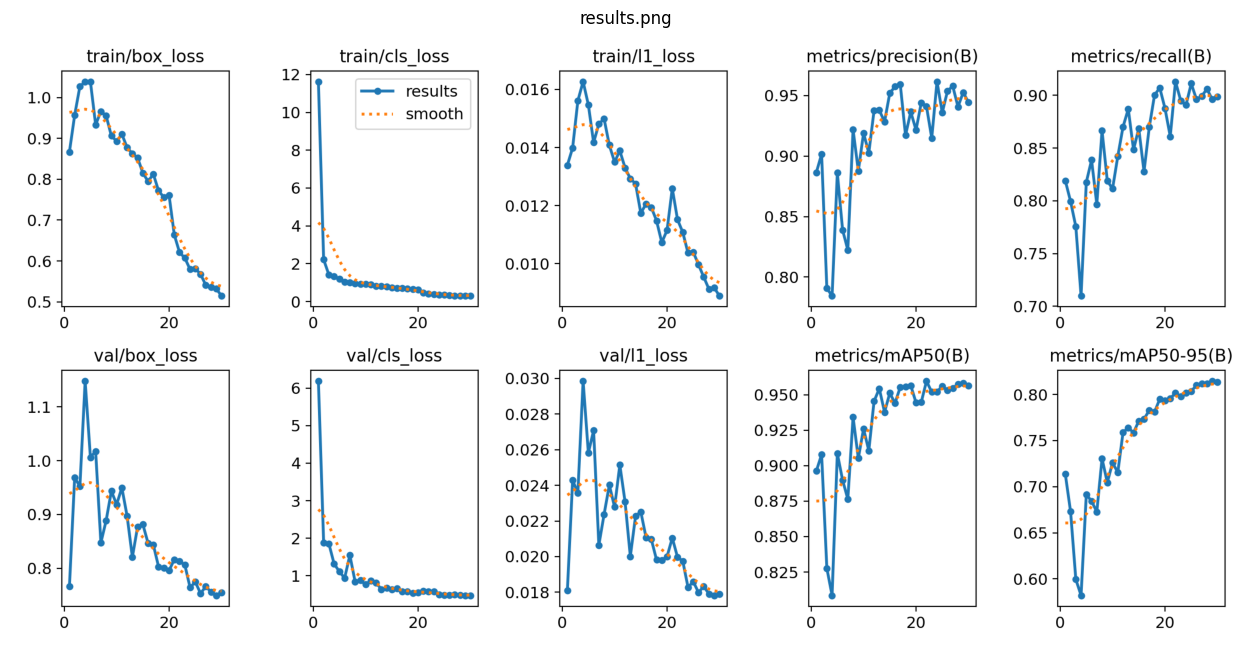

In [15]:
def show_file(pattern, size=(16, 8)):
    hits = sorted(run_dir.glob(pattern))
    if hits:
        plt.figure(figsize=size); plt.imshow(Image.open(hits[0])); plt.axis("off"); plt.title(hits[0].name); plt.show()
    else:
        print("Not found:", pattern)

show_file("results.png")

**Discussion:** Look at the curves: are training and validation losses both decreasing? Has mAP plateaued, and would more epochs help?

### 6.2 Confusion matrix and PR curve

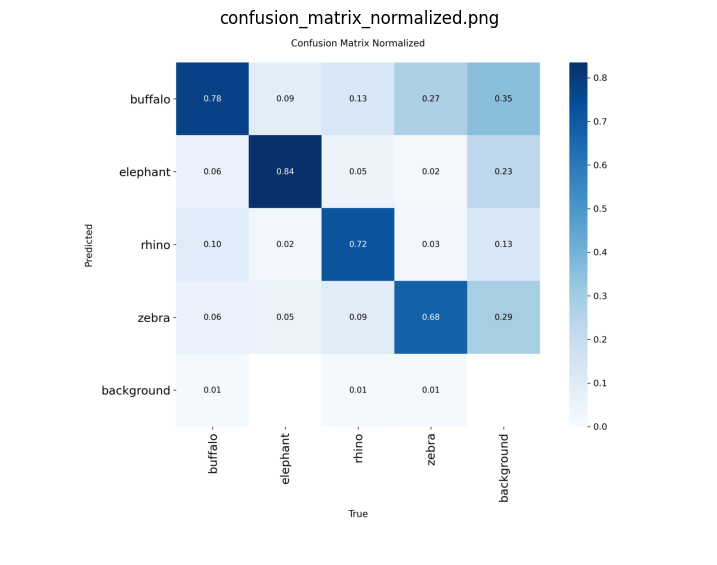

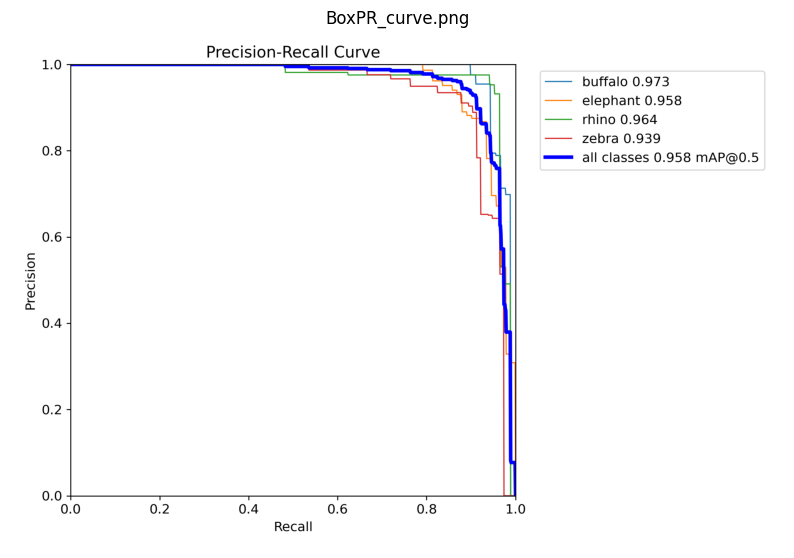

In [16]:
show_file("confusion_matrix_normalized.png", size=(9, 8))
show_file("*PR_curve.png", size=(10, 7))

**Reading the confusion matrix:** the extra **"background"** row and column are unique to detection.
- Columns are the **true** class, rows are the **predicted** class.
- *Background* column → the model predicted an animal **where there was none** (false positive)
- *Background* row → a real animal the model **missed entirely** (false negative)

Which classes get confused with each other? Does it make visual sense (e.g. buffalo vs. rhino)?

### 6.3 Final scores on the held-out **test** set

In [17]:
best = YOLO(run_dir / "weights" / "best.pt")
split = "test" if data.get("test") else "val"
m = best.val(data="african-wildlife.yaml", split=split, plots=False, verbose=False)

print(f"=== {split.upper()} SET ===")
print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}\n")
print(f"{'class':<10}{'P':>8}{'R':>8}{'AP50':>8}{'AP50-95':>9}")
for i, c in enumerate(m.box.ap_class_index):
    print(f"{names[int(c)]:<10}{m.box.p[i]:>8.3f}{m.box.r[i]:>8.3f}{m.box.ap50[i]:>8.3f}{m.box.ap[i]:>9.3f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1098.1±610.8 MB/s, size: 53.5 KB)
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.0Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.1it/s 2.5s
                   all        227        375      0.946      0.953      0.974      0.849
Speed: 0.7ms preprocess, 5.4ms inference, 0.0ms loss, 1.3ms postprocess per image
=== TEST SET ===
Precision 0.946 | Recall 0.953 | mAP50 0.974 | mAP50-95 0.849

class            P       R    AP50  AP50-95
buffalo      0.954   0.933   0.956    0.865
elephant     0.950   0.955   0.976    0.812
rhino        0.974  

### 6.4 Failure analysis: find the model's worst images
Aggregate metrics hide *where* the model fails. We match predictions to ground truth **using the IoU function from Part 1**, count true positives (TP), false positives (FP) and false negatives (FN) per image, then look at the worst cases.

In [18]:
def match_image(gt, preds, iou_thr=0.5):
    # Greedy matching. gt: [(cls, box)], preds: [(cls, conf, box)] -> (tp, fp, fn)
    used, tp = set(), 0
    for c, conf, pb in sorted(preds, key=lambda p: -p[1]):
        best_iou, best_j = 0, -1
        for j, (gc, gb) in enumerate(gt):
            if j in used or gc != c:
                continue
            v = iou(pb, gb)
            if v > best_iou:
                best_iou, best_j = v, j
        if best_iou >= iou_thr:
            used.add(best_j); tp += 1
    return tp, len(preds) - tp, len(gt) - tp

eval_imgs = sorted(glob.glob(str(Path(data[split]) / "*.jpg")))
report = []
for res in best.predict(eval_imgs, conf=0.25, stream=True, verbose=False):
    preds = [(int(c), float(s), tuple(b)) for c, s, b in
             zip(res.boxes.cls.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.boxes.xyxy.cpu().numpy())]
    gt = load_gt(res.path)
    tp, fp, fn = match_image(gt, preds)
    report.append(dict(path=res.path, gt=gt, preds=preds, tp=tp, fp=fp, fn=fn))

TP, FP, FN = (sum(r[k] for r in report) for k in ("tp", "fp", "fn"))
print(f"Totals @conf=0.25, IoU=0.5 -> TP={TP}  FP={FP}  FN={FN}")
print(f"Precision={TP/(TP+FP):.3f}  Recall={TP/(TP+FN):.3f}")
print(f"Perfect images: {sum(r['fp']==0 and r['fn']==0 for r in report)}/{len(report)}")

Totals @conf=0.25, IoU=0.5 -> TP=358  FP=45  FN=17
Precision=0.888  Recall=0.955
Perfect images: 188/227


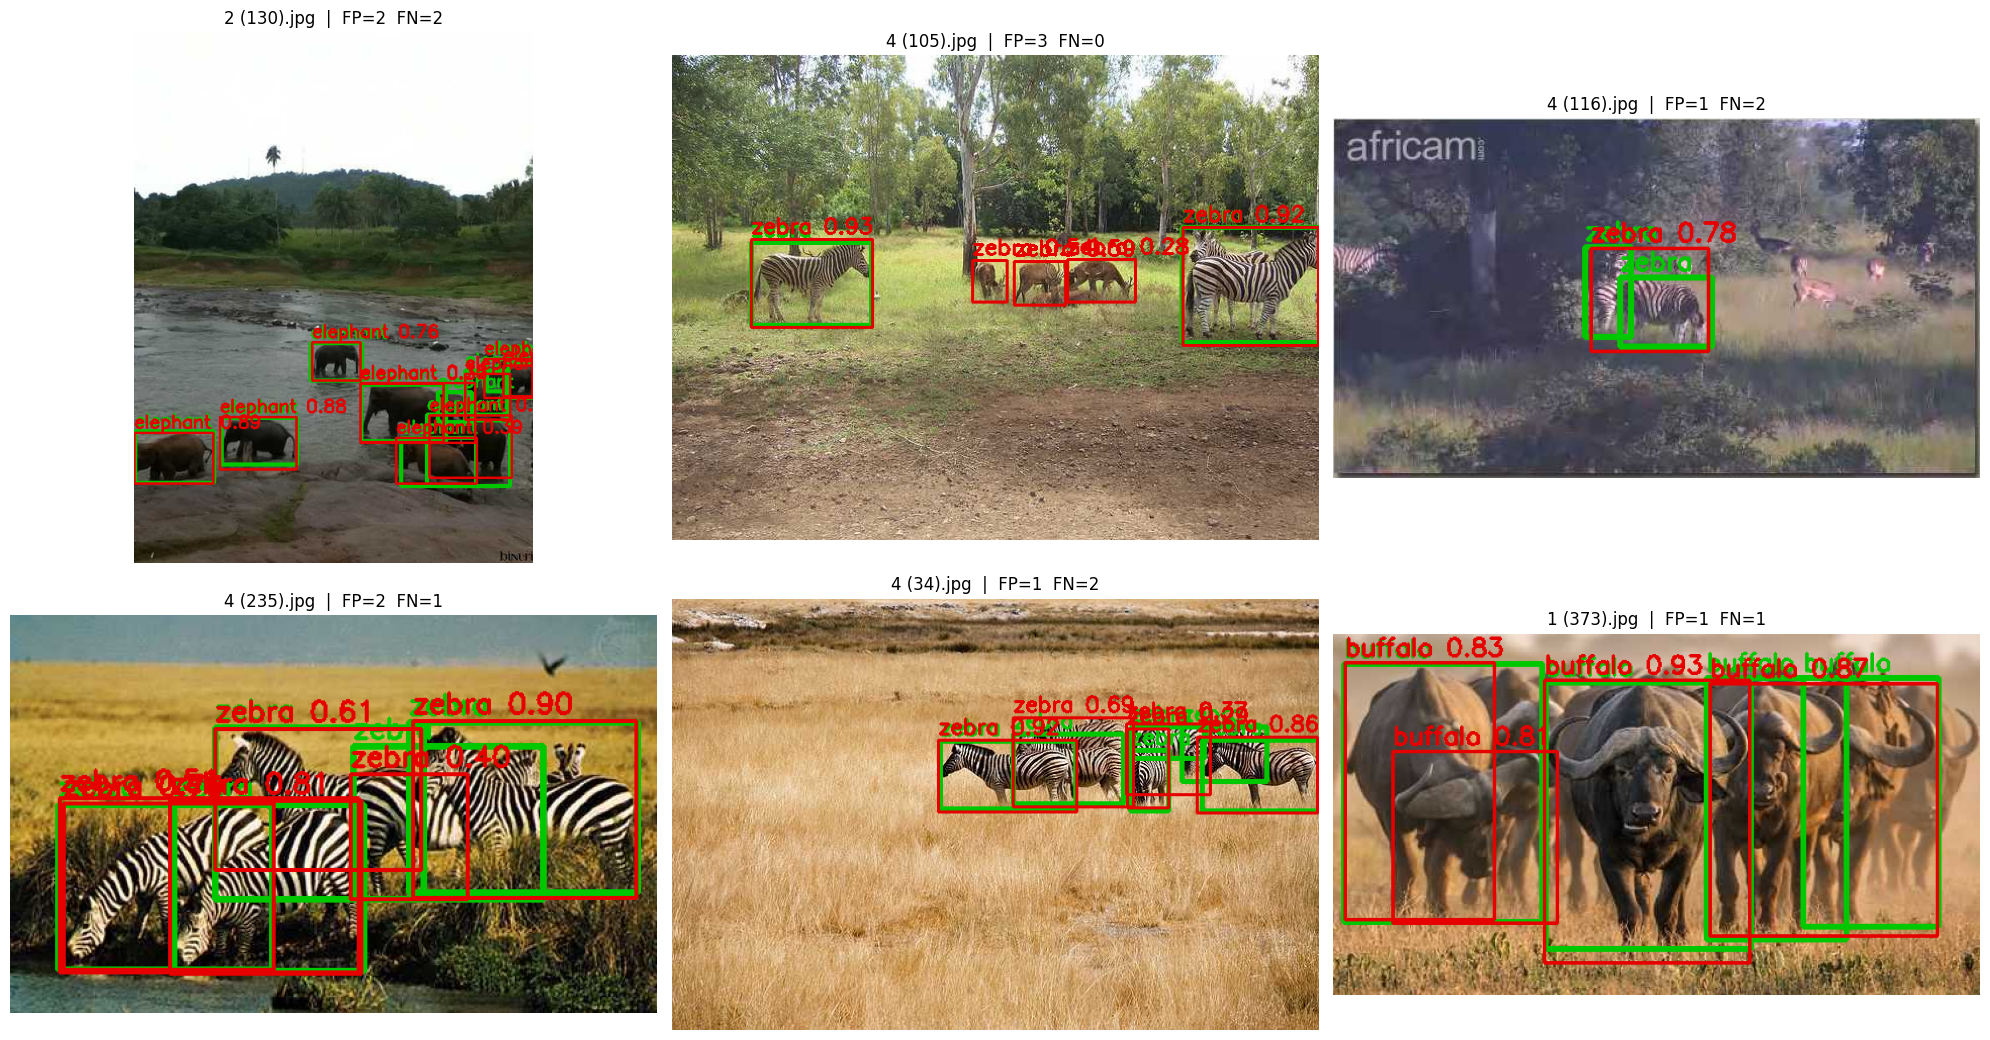

In [19]:
# Show the 6 worst images. GREEN = ground truth, RED = prediction
worst = sorted(report, key=lambda r: -(r["fp"] + r["fn"]))[:6]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, r in zip(axes.flat, worst):
    img = cv2.imread(r["path"])[:, :, ::-1].copy()
    draw_boxes(img, r["gt"], color=(0, 200, 0), thickness=4)
    draw_boxes(img, r["preds"], color=(230, 0, 0), thickness=2)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{Path(r['path']).name}  |  FP={r['fp']}  FN={r['fn']}")
plt.tight_layout(); plt.show()

**Diagnose each failure.** Common causes:
- **Occlusion / crowding**: animals overlapping each other
- **Small or distant objects**
- **Label noise**: is the *ground truth* itself wrong or missing?
- **Unusual conditions**: lighting, angle, partial view

Was your prediction from Part 4 correct? What **data** would you collect to fix the most common failure?

---
## Part 7: Using the Model

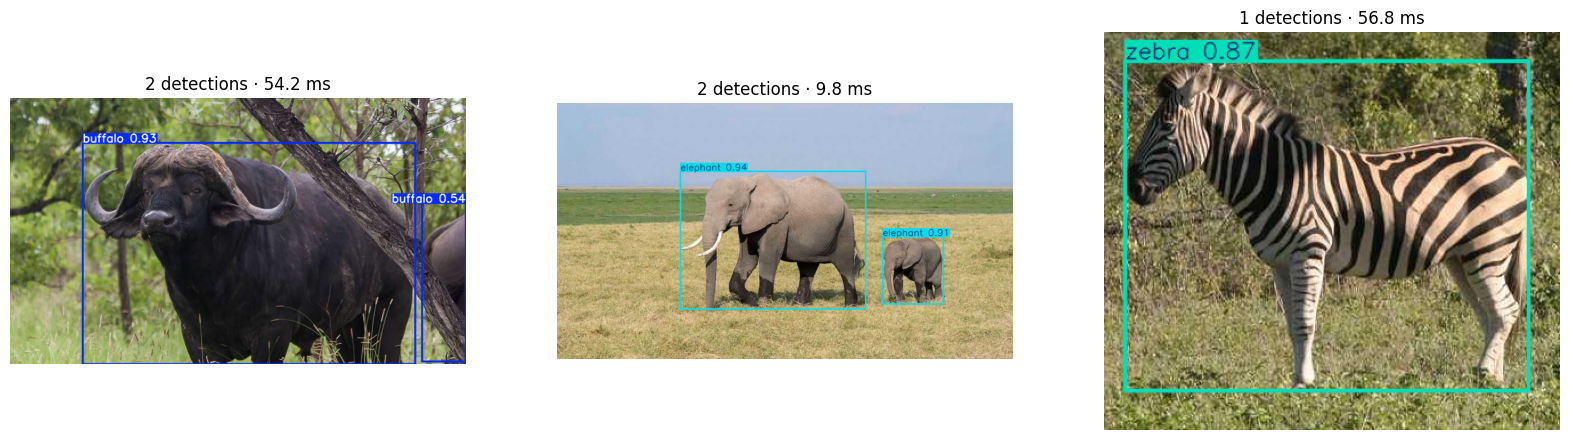

In [20]:
# Predict on random test images the model has never seen
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, p in zip(axes, random.sample(eval_imgs, 3)):
    res = best(p, conf=0.4, verbose=False)[0]
    ax.imshow(res.plot()[:, :, ::-1]); ax.axis("off")
    ax.set_title(f"{len(res.boxes)} detections · {res.speed['inference']:.1f} ms")
plt.show()

# Optional: run on your own safari photo (upload it first, leave as None to skip)
MY_SAFARI = None         # e.g. "my_safari.jpg"
if MY_SAFARI:
    show(best(MY_SAFARI, conf=0.4, verbose=False)[0].plot(), MY_SAFARI)

In [22]:
# Optional: process a video (upload an .mp4 first, leave as None to skip)
MY_VIDEO = "stock-footage-zebras-are-a-short-stocky-animal-that-is-generally-about-feet-long-and-stands-between-and.webm"          # e.g. "safari.mp4"
if MY_VIDEO:
    best.track(source=MY_VIDEO, conf=0.4, save=True)   # tracking: each animal keeps an ID; output under runs/detect/

# Export for deployment outside PyTorch (phones, browsers, edge devices)
onnx_path = best.export(format="onnx")
print("Exported:", onnx_path)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 189ms
Prepared 1 package in 48ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/349) /content/stock-footage-zebras-are-a-short-stocky-animal-that-is-generally-abou

---
## Part 8: Take-home Challenge (choose one)

1. **Build your own detector:** collect and label 40 to 60 photos of an everyday object (mug, phone, pen…) with [Roboflow](https://roboflow.com) or [CVAT](https://www.cvat.ai/). Export in YOLO format, train, and report mAP50 plus your worst failure case.
2. **Model-size experiment:** train `yolo26s.pt` on the same data. Compare mAP, training time and inference speed against nano. When is the bigger model worth it?
3. **Ablation study:** retrain with `mosaic=0.0`. How much does mAP change? Explain the result using your failure analysis.
4. **From-scratch metrics:** using `match_image`, sweep the confidence threshold from 0.05 to 0.95 and plot your own precision-recall curve. Compare it with the one Ultralytics generated.

**Deliverable:** a short notebook or 3 slides with your metrics, one failure case, and what you'd try next.